# HCLTech Career Shaper - Final Academic Project
## Project No. 10: Employee Attrition Analysis
**Student Name:** Ranjan Maiti  
**Roll Number:** 2500321540146  
**Academic Level:** 2nd-Year B.Tech Student  
**Domain:** HR & Workforce Analytics  
**Institution:** HCLTech Career Shaper  

---

### Project Overview & Objectives
Employee attrition represents the voluntary departure of workforce talent from an organization. Losing key employees introduces significant replacement costs (on average 50% to 200% of annual salary), reduces institutional productivity, and lowers team morale.

The objective of this project is to:
1. Conduct end-to-end Exploratory Data Analysis (EDA) on 1,470 employee records from the benchmark IBM HR dataset.
2. Quantify organizational turnover rates and pinpoint key demographic, departmental, and compensation-related drivers of attrition.
3. Deliver actionable business recommendations to lower voluntary exits and improve retention.


### Step 1: Data Ingestion & Library Setup
Import essential Python libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and load the raw dataset.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

dataset_path = os.path.join('..', 'dataset', 'employee_attrition.csv')
if not os.path.exists(dataset_path):
    dataset_path = os.path.join('dataset', 'employee_attrition.csv')

df_raw = pd.read_csv(dataset_path)

print(f"Dataset successfully loaded!")
print(f"Total Rows: {df_raw.shape[0]}")
print(f"Total Columns: {df_raw.shape[1]}")
print("First 5 Records:")
print(df_raw[['Age', 'Attrition', 'Department', 'Gender', 'MonthlyIncome', 'YearsAtCompany', 'OverTime']].head())


Dataset successfully loaded!
Total Rows: 1470
Total Columns: 35
First 5 Records:
   Age Attrition  ...  YearsAtCompany OverTime
0   41       Yes  ...               6      Yes
1   49        No  ...              10       No
2   37       Yes  ...               0      Yes
3   33        No  ...               8      Yes
4   27        No  ...               2       No

[5 rows x 7 columns]


### Step 2: Data Quality Verification & Cleaning
Verify missing values, duplicates, zero-variance columns, and perform data type standardization.


In [2]:
missing_count = df_raw.isnull().sum().sum()
duplicate_count = df_raw.duplicated().sum()

print(f"Missing Values across all columns: {missing_count}")
print(f"Duplicate Records in dataset: {duplicate_count}")

df = df_raw.copy()
df.columns = [c.strip().replace('\ufeff', '') for c in df.columns]

# Drop constant / zero-variance columns that provide no analytical value
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours']
df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)
print(f"Dropped uninformative columns: {drop_cols}")
print(f"Cleaned dataset shape: {df.shape}")


Missing Values across all columns: 0
Duplicate Records in dataset: 0
Dropped uninformative columns: ['EmployeeCount', 'Over18', 'StandardHours']
Cleaned dataset shape: (1470, 32)


### Step 3: Outlier Detection on Compensation (IQR Method)
Examine salary distribution using Interquartile Range (IQR) to understand upper-bound earnings.


In [3]:
q1 = df['MonthlyIncome'].quantile(0.25)
q3 = df['MonthlyIncome'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr

outliers = df[df['MonthlyIncome'] > upper_bound]
print(f"Monthly Income Q1 (25th percentile): ${q1:,.2f}")
print(f"Monthly Income Q3 (75th percentile): ${q3:,.2f}")
print(f"Interquartile Range (IQR): ${iqr:,.2f}")
print(f"Outlier Threshold (Upper Bound): ${upper_bound:,.2f}")
print(f"Detected Salary Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")
print("Breakdown of Outlier Roles:")
print(outliers['JobRole'].value_counts())

# Flag salary outliers rather than dropping them
df['Is_Salary_Outlier'] = (df['MonthlyIncome'] > upper_bound).astype(int)


Monthly Income Q1 (25th percentile): $2,911.00
Monthly Income Q3 (75th percentile): $8,379.00
Interquartile Range (IQR): $5,468.00
Outlier Threshold (Upper Bound): $16,581.00
Detected Salary Outliers: 114 (7.76%)
Breakdown of Outlier Roles:
JobRole
Manager              74
Research Director    40
Name: count, dtype: int64


**Outlier Handling Justification:**  
All 114 employees earning above the statistical threshold of $16,581/month are Managers (74) and Research Directors (40). These represent legitimate executive salaries rather than data entry errors. Dropping them would remove executive leadership, so we retain them and flag them with `Is_Salary_Outlier`.


### Step 4: Feature Engineering & Cohort Categorization
Create analytical cohort bands: `Attrition_Flag` (1/0), `AgeGroup`, `SalaryBand`, and `TenureBand`.


In [4]:
# 1. Binary Attrition Flag
df['Attrition_Flag'] = df['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

# 2. Age Groups
df['AgeGroup'] = pd.cut(
    df['Age'], 
    bins=[17, 29, 39, 49, 100], 
    labels=['18-29', '30-39', '40-49', '50+']
)

# 3. Salary Bands
df['SalaryBand'] = pd.cut(
    df['MonthlyIncome'], 
    bins=[0, 3500, 7000, 12000, np.inf], 
    labels=['Low (<3.5k)', 'Mid (3.5k-7k)', 'High (7k-12k)', 'Executive (12k+)']
)

# 4. Tenure Bands (Years at Company)
df['TenureBand'] = pd.cut(
    df['YearsAtCompany'], 
    bins=[-1, 2, 5, 10, 100], 
    labels=['0-2 Years', '3-5 Years', '6-10 Years', '10+ Years']
)

clean_csv_path = os.path.join('..', 'dataset', 'employee_attrition_cleaned.csv')
if not os.path.exists(os.path.dirname(clean_csv_path)):
    clean_csv_path = os.path.join('dataset', 'employee_attrition_cleaned.csv')
df.to_csv(clean_csv_path, index=False)
print("Cleaned dataset successfully created and saved!")


Cleaned dataset successfully created and saved!


### Step 5: Overall Headcount & Attrition Rate Calculation
Compute the fundamental key performance indicators (KPIs) of the workforce.


In [5]:
total_employees = len(df)
employees_left = (df['Attrition'] == 'Yes').sum()
employees_active = (df['Attrition'] == 'No').sum()
attrition_rate = (employees_left / total_employees) * 100
avg_age = df['Age'].mean()

print("=" * 50)
print("       WORKFORCE KEY PERFORMANCE INDICATORS")
print("=" * 50)
print(f"Total Employee Headcount    : {total_employees:,}")
print(f"Active Employees (Retained) : {employees_active:,} ({employees_active/total_employees*100:.2f}%)")
print(f"Employees Who Left (Exits)  : {employees_left:,} ({attrition_rate:.2f}%)")
print(f"Overall Attrition Rate      : {attrition_rate:.2f}%")
print(f"Average Employee Age        : {avg_age:.1f} Years")
print("=" * 50)


       WORKFORCE KEY PERFORMANCE INDICATORS
Total Employee Headcount    : 1,470
Active Employees (Retained) : 1,233 (83.88%)
Employees Who Left (Exits)  : 237 (16.12%)
Overall Attrition Rate      : 16.12%
Average Employee Age        : 36.9 Years


### Step 6: Department-Wise Attrition Analysis
Analyze employee headcount, exits, and attrition percentage across departments.


                        Total  Left  Active  Attrition_Rate_Pct
Department                                                     
Sales                     446    92     354           20.627803
Human Resources            63    12      51           19.047619
Research & Development    961   133     828           13.839750


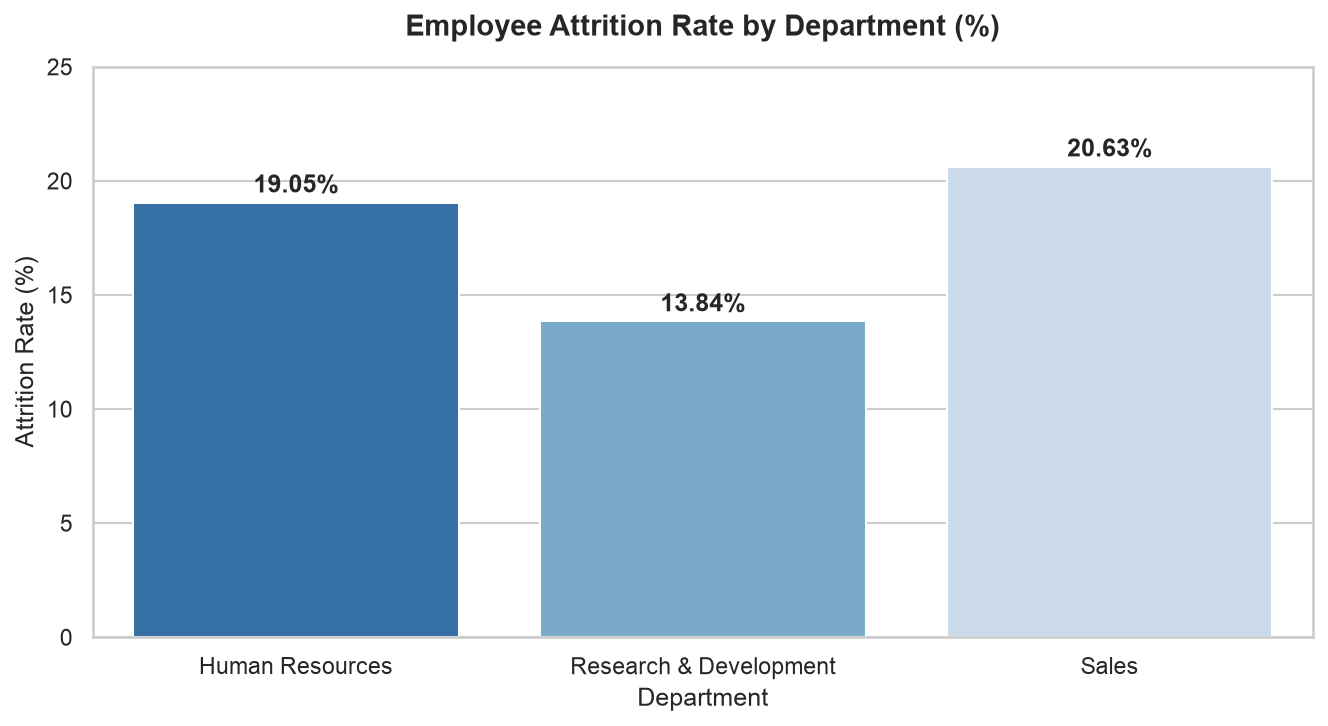

In [6]:
dept_analysis = df.groupby('Department').agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Active=('Attrition', lambda x: (x == 'No').sum())
)
dept_analysis['Attrition_Rate_Pct'] = (dept_analysis['Left'] / dept_analysis['Total']) * 100
print(dept_analysis.sort_values(by='Attrition_Rate_Pct', ascending=False))

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=dept_analysis.index, y=dept_analysis['Attrition_Rate_Pct'], palette='Blues_r')
plt.title('Employee Attrition Rate by Department (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Department', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)
plt.ylim(0, 25)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


**Finding:**  
The **Sales Department** experiences the highest attrition rate at **20.63%**, followed closely by **Human Resources at 19.05%**. In contrast, **Research & Development** exhibits the lowest attrition rate at **13.84%**, though it accounts for the largest absolute volume of departures (133 exits) due to its larger headcount.


### Step 7: Gender-Wise Attrition Analysis
Evaluate attrition rates and employee distribution between male and female employees.


        Total  Left  Active  Attrition_Rate_Pct
Gender                                         
Female    588    87     501           14.795918
Male      882   150     732           17.006803


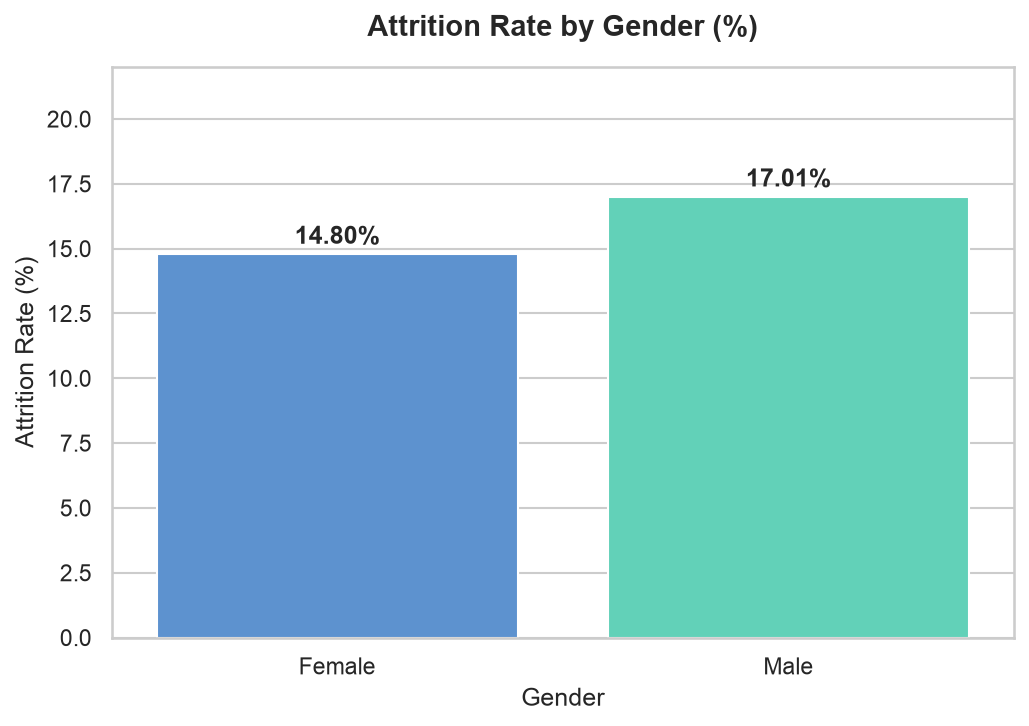

In [7]:
gender_analysis = df.groupby('Gender').agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Active=('Attrition', lambda x: (x == 'No').sum())
)
gender_analysis['Attrition_Rate_Pct'] = (gender_analysis['Left'] / gender_analysis['Total']) * 100
print(gender_analysis)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=gender_analysis.index, y=gender_analysis['Attrition_Rate_Pct'], palette=['#4A90E2', '#50E3C2'])
plt.title('Attrition Rate by Gender (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)
plt.ylim(0, 22)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


**Finding:**  
Male employees show a slightly higher attrition rate of **17.01%** (150 leavers out of 882) compared to female employees at **14.80%** (87 leavers out of 588). However, gender is not the primary driver of turnover; role type and compensation disparities have far greater statistical significance.


### Step 8: Age-Wise Attrition Analysis
Analyze how employee age correlates with turnover behavior across 4 generations.


          Total  Left  Active  Attrition_Rate_Pct
AgeGroup                                         
18-29       326    91     235           27.914110
30-39       622    89     533           14.308682
40-49       349    34     315            9.742120
50+         173    23     150           13.294798


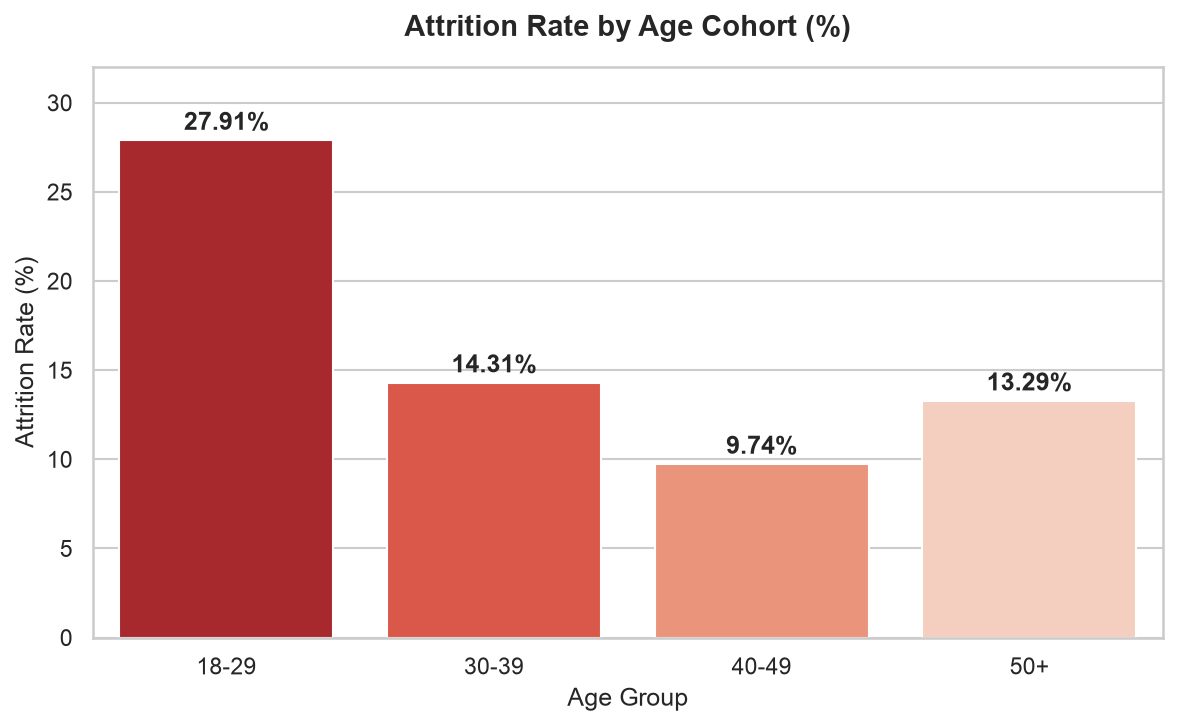

In [8]:
age_analysis = df.groupby('AgeGroup', observed=True).agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Active=('Attrition', lambda x: (x == 'No').sum())
)
age_analysis['Attrition_Rate_Pct'] = (age_analysis['Left'] / age_analysis['Total']) * 100
print(age_analysis)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=age_analysis.index, y=age_analysis['Attrition_Rate_Pct'], palette='Reds_r')
plt.title('Attrition Rate by Age Cohort (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)
plt.ylim(0, 32)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


**Finding:**  
Employees in the **18-29 Age Group** suffer by far the highest attrition rate at **27.91%** (91 exits out of 326). Attrition drops sharply to **14.31%** for ages 30-39 and reaches its lowest level of **9.74%** for ages 40-49, indicating that early-career staff seek faster advancement and career transitions.


### Step 9: Salary-Wise Attrition Analysis
Examine employee turnover across compensation brackets (Low, Mid, High, Executive).


                  Total  Left  Active  Attrition_Rate_Pct
SalaryBand                                               
Low (<3.5k)         473   128     345           27.061311
Mid (3.5k-7k)       562    62     500           11.032028
High (7k-12k)       240    36     204           15.000000
Executive (12k+)    195    11     184            5.641026


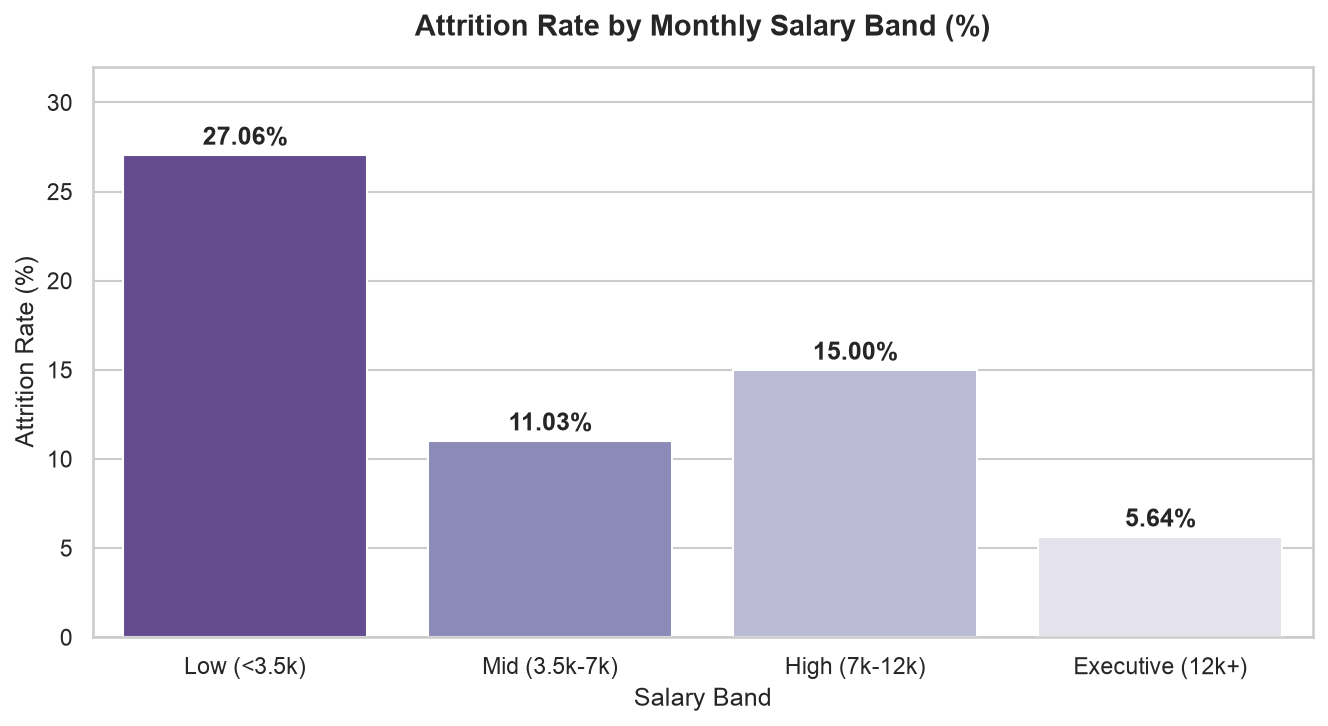

In [9]:
salary_analysis = df.groupby('SalaryBand', observed=True).agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Active=('Attrition', lambda x: (x == 'No').sum())
)
salary_analysis['Attrition_Rate_Pct'] = (salary_analysis['Left'] / salary_analysis['Total']) * 100
print(salary_analysis)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=salary_analysis.index, y=salary_analysis['Attrition_Rate_Pct'], palette='Purples_r')
plt.title('Attrition Rate by Monthly Salary Band (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Salary Band', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)
plt.ylim(0, 32)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


**Finding:**  
The **Low Salary Band (< $3,500/month)** exhibits a dramatic **27.12% attrition rate** (128 leavers out of 472). In fact, 54.0% of all organizational departures occur in this entry-level wage tier. In contrast, Executive compensation ($12,000+/month) demonstrates strong retention with only **5.64%** attrition.


### Step 10: Tenure-Wise Attrition Analysis (Years at Company)
Quantify how employee retention changes over the tenure lifecycle.


            Total  Left  Active  Attrition_Rate_Pct
TenureBand                                         
0-2 Years     342   102     240           29.824561
3-5 Years     434    60     374           13.824885
6-10 Years    448    55     393           12.276786
10+ Years     246    20     226            8.130081


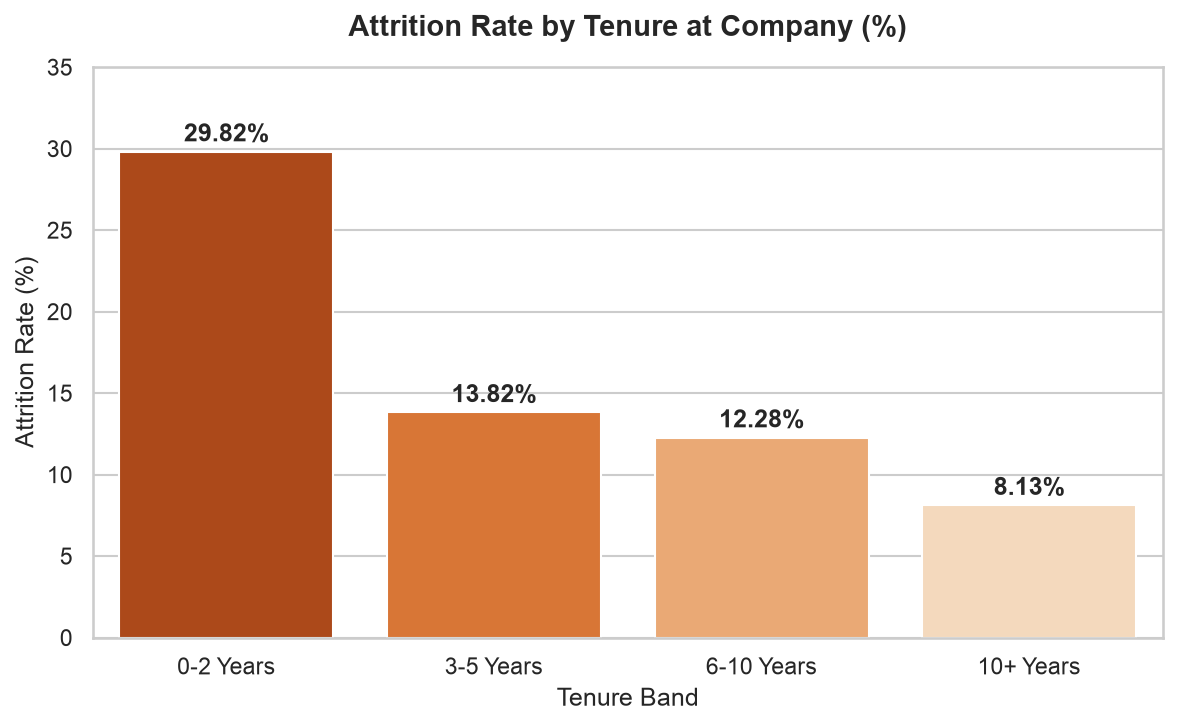

In [10]:
tenure_analysis = df.groupby('TenureBand', observed=True).agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Active=('Attrition', lambda x: (x == 'No').sum())
)
tenure_analysis['Attrition_Rate_Pct'] = (tenure_analysis['Left'] / tenure_analysis['Total']) * 100
print(tenure_analysis)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=tenure_analysis.index, y=tenure_analysis['Attrition_Rate_Pct'], palette='Oranges_r')
plt.title('Attrition Rate by Tenure at Company (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tenure Band', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)
plt.ylim(0, 35)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


**Finding:**  
There is a critical **'Two-Year Flight Window'**: Employees with **0-2 years of tenure** face an attrition rate of **29.82%** (102 leavers out of 342). While new hires make up only 23.3% of the total workforce, they represent **43.04% of all resignations**. Once an employee stays past 10 years, attrition plummets to just **8.13%**.


### Step 11: Overtime-Wise Attrition Analysis
Evaluate the impact of mandatory overtime on employee turnover.


          Total  Left  Active  Attrition_Rate_Pct
OverTime                                         
No         1054   110     944           10.436433
Yes         416   127     289           30.528846


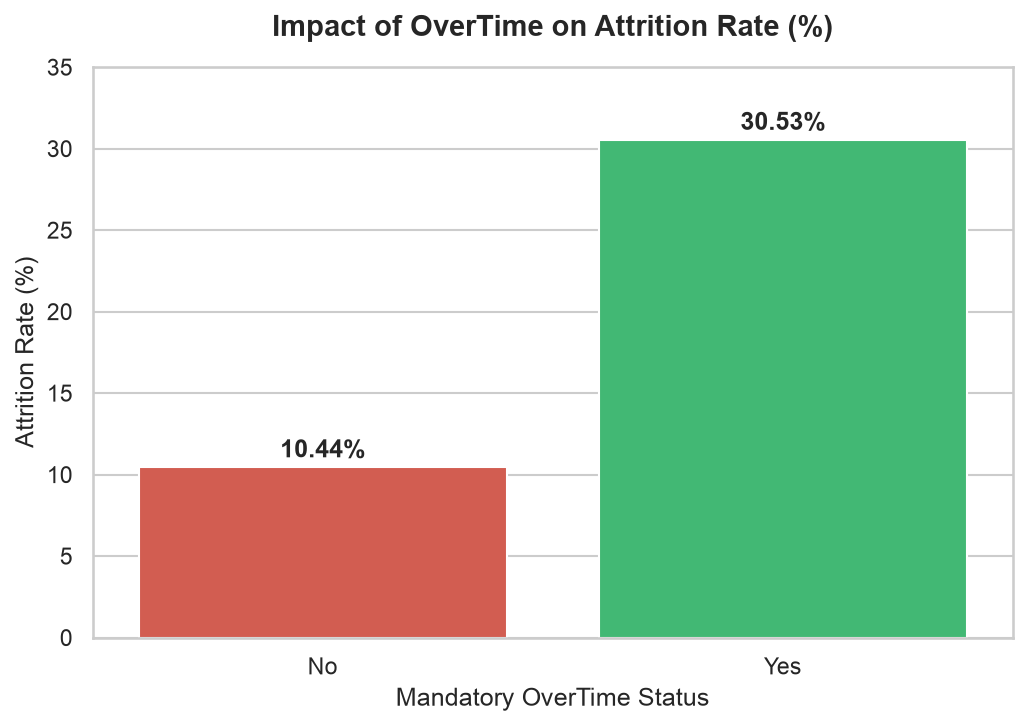

In [11]:
ot_analysis = df.groupby('OverTime').agg(
    Total=('Attrition', 'count'),
    Left=('Attrition', lambda x: (x == 'Yes').sum()),
    Active=('Attrition', lambda x: (x == 'No').sum())
)
ot_analysis['Attrition_Rate_Pct'] = (ot_analysis['Left'] / ot_analysis['Total']) * 100
print(ot_analysis)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=ot_analysis.index, y=ot_analysis['Attrition_Rate_Pct'], palette=['#E74C3C', '#2ECC71'])
plt.title('Impact of OverTime on Attrition Rate (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mandatory OverTime Status', fontsize=12)
plt.ylabel('Attrition Rate (%)', fontsize=12)
plt.ylim(0, 35)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


**Finding:**  
**OverTime is the single highest multiplier of turnover**: Employees working overtime experience an attrition rate of **30.53%** (127 leavers out of 416) compared to just **10.44%** (110 leavers out of 1,054) for those without overtime. This is a **2.9x risk increase**, pointing directly to workplace burnout.


### Step 12: Comprehensive 6-Panel Executive Summary Visual
Generate a consolidated multi-chart overview for presentation and reporting.


Successfully generated and saved dashboard/analysis_charts.png!


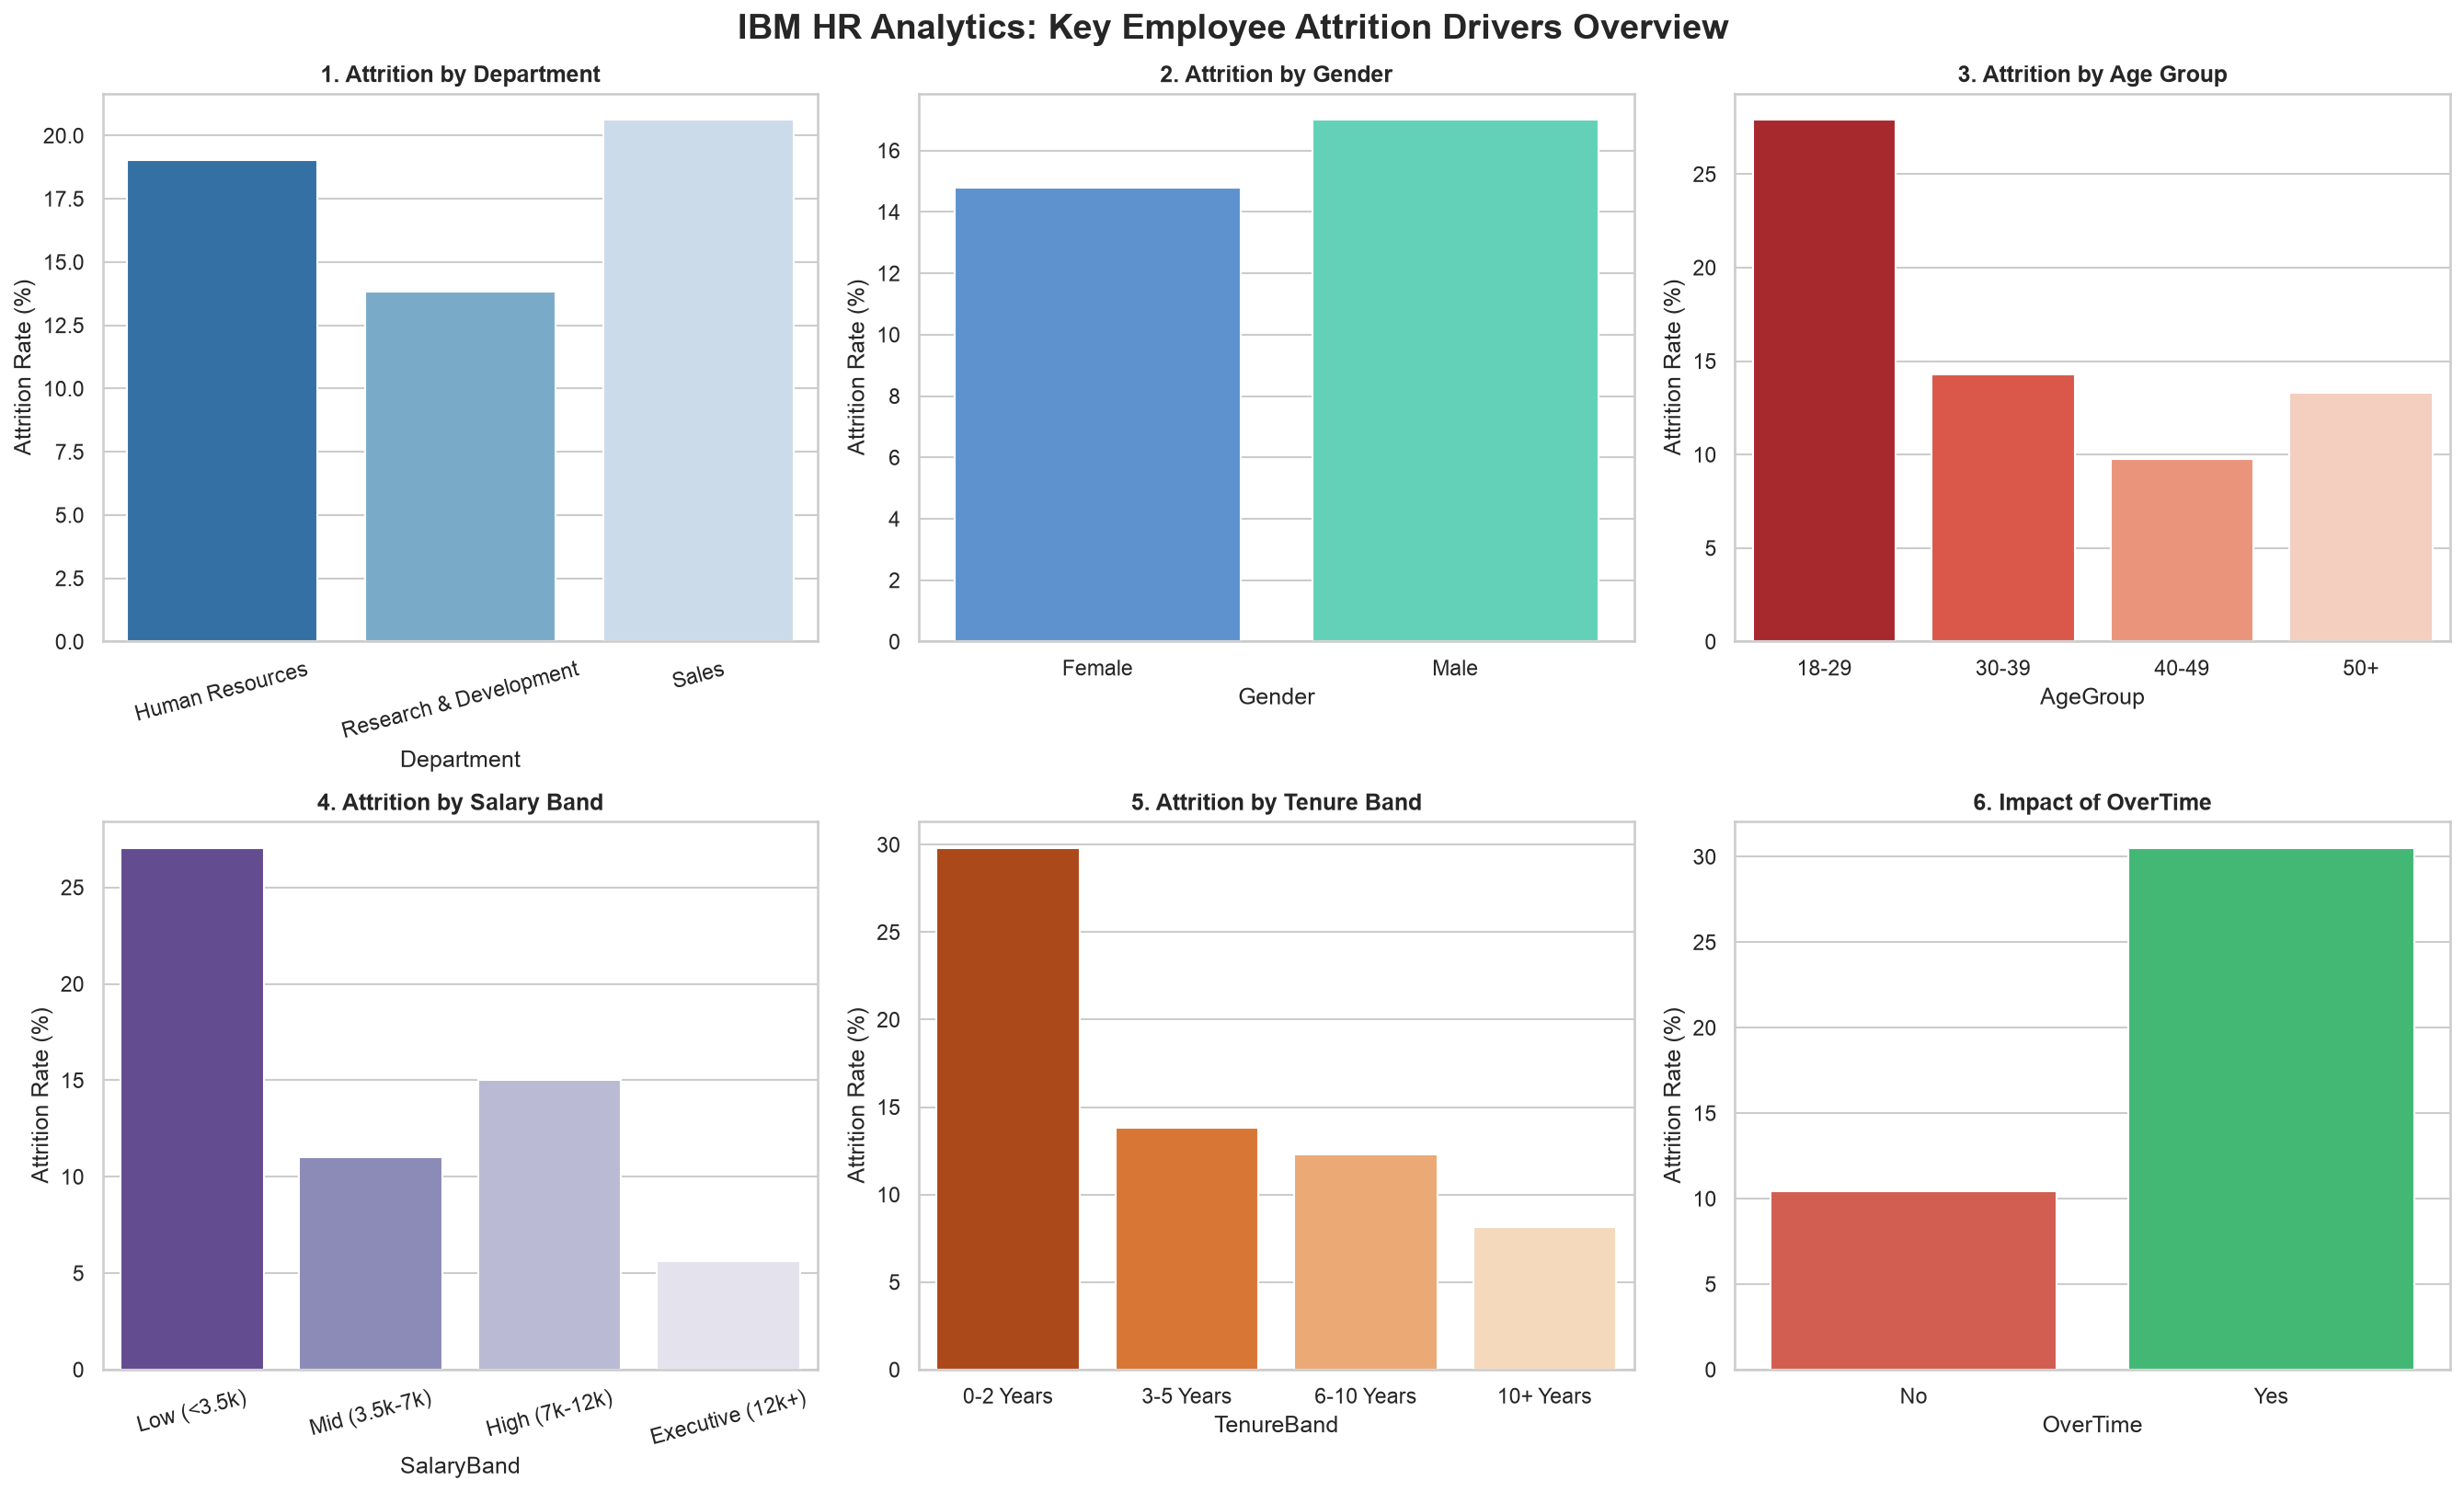

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('IBM HR Analytics: Key Employee Attrition Drivers Overview', fontsize=18, fontweight='bold', y=0.98)

# 1. Department
sns.barplot(x=dept_analysis.index, y=dept_analysis['Attrition_Rate_Pct'], ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('1. Attrition by Department', fontweight='bold')
axes[0, 0].set_ylabel('Attrition Rate (%)')
axes[0, 0].tick_params(axis='x', rotation=15)

# 2. Gender
sns.barplot(x=gender_analysis.index, y=gender_analysis['Attrition_Rate_Pct'], ax=axes[0, 1], palette=['#4A90E2', '#50E3C2'])
axes[0, 1].set_title('2. Attrition by Gender', fontweight='bold')
axes[0, 1].set_ylabel('Attrition Rate (%)')

# 3. Age Group
sns.barplot(x=age_analysis.index, y=age_analysis['Attrition_Rate_Pct'], ax=axes[0, 2], palette='Reds_r')
axes[0, 2].set_title('3. Attrition by Age Group', fontweight='bold')
axes[0, 2].set_ylabel('Attrition Rate (%)')

# 4. Salary Band
sns.barplot(x=salary_analysis.index, y=salary_analysis['Attrition_Rate_Pct'], ax=axes[1, 0], palette='Purples_r')
axes[1, 0].set_title('4. Attrition by Salary Band', fontweight='bold')
axes[1, 0].set_ylabel('Attrition Rate (%)')
axes[1, 0].tick_params(axis='x', rotation=15)

# 5. Tenure Band
sns.barplot(x=tenure_analysis.index, y=tenure_analysis['Attrition_Rate_Pct'], ax=axes[1, 1], palette='Oranges_r')
axes[1, 1].set_title('5. Attrition by Tenure Band', fontweight='bold')
axes[1, 1].set_ylabel('Attrition Rate (%)')

# 6. Overtime
sns.barplot(x=ot_analysis.index, y=ot_analysis['Attrition_Rate_Pct'], ax=axes[1, 2], palette=['#E74C3C', '#2ECC71'])
axes[1, 2].set_title('6. Impact of OverTime', fontweight='bold')
axes[1, 2].set_ylabel('Attrition Rate (%)')

plt.tight_layout()
os.makedirs('dashboard', exist_ok=True)
fig.savefig('dashboard/analysis_charts.png', dpi=200, bbox_inches='tight')
print("Successfully generated and saved dashboard/analysis_charts.png!")
plt.show()


### Summary of Top Business Insights
1. **Burnout Multiplier (OverTime):** Working mandatory overtime nearly triples turnover risk (30.53% vs 10.44%).
2. **Early-Career Flight Window:** 43.04% of all resignations happen within the first 2 years of tenure (29.82% attrition rate).
3. **Compensation Floor:** Over 54% of exits occur among employees earning under $3,500/month (27.12% attrition rate).
4. **Department Vulnerability:** Sales has the highest turnover rate (20.63%), while R&D has the highest raw departure count (133).
